# EGS sweep: what controls total thermal production?

The response is **total thermal production** $E$ (`E_total_GWh`): the heat extracted over
the run,

$$E = \int_0^{t_\mathrm{end}} \dot m\, c_f\,\big(T_\mathrm{out}(t) - T_\mathrm{inj}\big)\,dt,$$

so it already accounts for cooling: as the rock around the fractures cools, $T_\mathrm{out}$
falls and so does the heat produced.

Data: `results/master_results.csv`, one row per run. The notebook finds the inputs the
sweep varied and works with those, so it runs unchanged on any sweep from
`make_yaml_file.py`.

1. Load the runs and find the swept inputs
2. Total production across the sweep
3. Each input against total production
4. Multivariate regression (linear, then with curvature and interactions)
5. Random forest: importance and the shape of each effect
6. Best and worst designs

Run from `graph_based/` (or set `CSV` below).

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

CSV = "results/master_results.csv"
RESPONSE = "E_total_GWh"

# figure style (same inks as plot_results.py)
BLUE, ORANGE = "#2a78d6", "#eb6834"
TEXT, TEXT_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2, "axes.titlecolor": TEXT,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110,
})

## 1. Load the runs and find the swept inputs

Inputs are the config columns that vary across runs. `domain.seed` is left out (it only
matters with stochastic fractures, and then as noise rather than a control), and the
pressure drop `dp = p_in - p_out` stands in for the two pressures. Anything spanning more
than a factor of 30 is analysed in log10.

In [4]:
df = pd.read_csv(CSV)
df["dp_MPa"] = (df["flow.p_in"] - df["flow.p_out"]) / 1e6

config_cols = [c for c in df.columns if "." in c]
INPUTS = [c for c in config_cols if df[c].nunique() > 1 and c not in ("domain.seed", "flow.p_in", "flow.p_out")]
if df["dp_MPa"].nunique() > 1:
    INPUTS.append("dp_MPa")

NAMES = {"hydraulic_fractures.number": "HF number", "hydraulic_fractures.radius": "HF radius [m]",
         "hydraulic_fractures.aspect": "HF aspect", "hydraulic_fractures.aperture": "HF aperture [m]",
         "hydraulic_fractures.length": "HF zone length [m]", "wells.aperture": "well aperture [m]",
         "wells.lateral_y": "well half-spacing [m]", "dp_MPa": "dp [MPa]"}
short = lambda c: NAMES.get(c, c.split(".")[-1])


def spans_decades(x):
    x = np.asarray(x, float)
    return x.min() > 0 and x.max() / x.min() > 30


LOG_INPUTS = [c for c in INPUTS if spans_decades(df[c])]
LOG_E = spans_decades(df[RESPONSE])
INTEGER_INPUTS = [c for c in INPUTS if np.allclose(df[c], df[c].round())]

# regression design matrix: log10 for log inputs, as-is otherwise
label = lambda c: f"log10 {short(c)}" if c in LOG_INPUTS else short(c)
X = pd.DataFrame({label(c): (np.log10(df[c]) if c in LOG_INPUTS else df[c].astype(float)) for c in INPUTS})
y = np.log10(df[RESPONSE].values) if LOG_E else df[RESPONSE].values
y_name = "log10 E" if LOG_E else "E [GWh]"

print(f"{len(df)} runs; swept inputs: {[short(c) for c in INPUTS]}; response analysed as {y_name}")
fixed = {short(c): df[c].iloc[0] for c in ("hydraulic_fractures.number", "hydraulic_fractures.radius",
                                           "hydraulic_fractures.aspect", "hydraulic_fractures.aperture",
                                           "wells.aperture", "dp_MPa", "thermal.t_end_years")
         if c in df and df[c].nunique() == 1}
print("fixed in this sweep:", fixed)
if len(df) < 3 * (len(INPUTS) + 1):
    print(f"note: {len(df)} runs for {len(INPUTS)} inputs; the regressions below will be rough")
df[INPUTS + [RESPONSE]].describe().T[["mean", "std", "min", "50%", "max"]]

2 runs; swept inputs: ['HF number', 'HF radius [m]', 'HF aspect']; response analysed as E [GWh]
fixed in this sweep: {'HF aperture [m]': np.float64(0.0001), 'well aperture [m]': np.float64(0.001), 'dp [MPa]': np.float64(1.0), 't_end_years': np.int64(30)}
note: 2 runs for 3 inputs; the regressions below will be rough


,mean,std,min,50%,max
hydraulic_fractures.number,7.500000,4.949747,4.000000,7.500000,11.000000
hydraulic_fractures.radius,66.535080,9.048183,60.137048,66.535080,72.933112
hydraulic_fractures.aspect,1.811692,0.655353,1.348288,1.811692,2.275096
E_total_GWh,40.522998,25.913552,22.199350,40.522998,58.846647


## 2. Total production across the sweep

The spread of $E$ is what the inputs have to explain: the left panel is its distribution,
the right one the runs ranked from most to least heat.

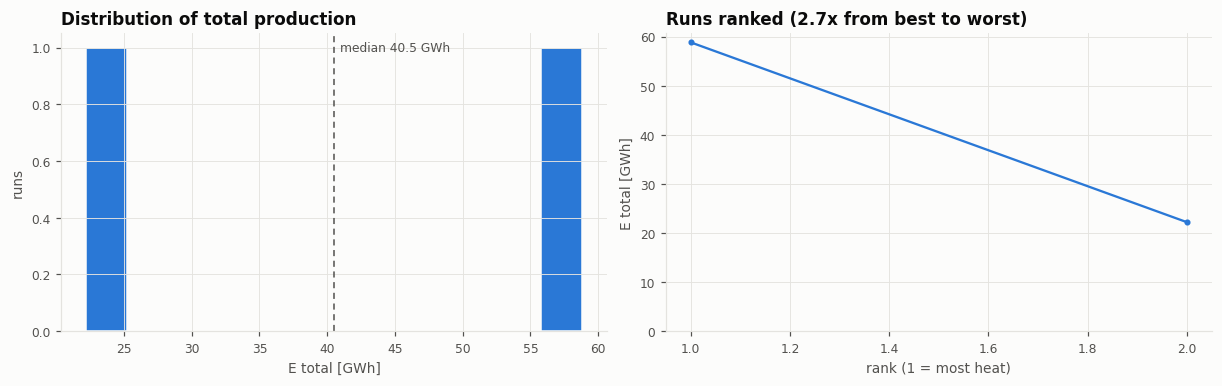

In [5]:
E = df[RESPONSE]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
bins = np.logspace(np.log10(E.min()), np.log10(E.max()), 12) if LOG_E else 12
axes[0].hist(E, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1)
axes[0].axvline(E.median(), color=TEXT_2, linewidth=1, linestyle=(0, (4, 3)))
axes[0].annotate(f"median {E.median():.1f} GWh", (E.median(), axes[0].get_ylim()[1]), xytext=(4, -12),
                 textcoords="offset points", fontsize=8, color=TEXT_2)
if LOG_E:
    axes[0].set_xscale("log")
axes[0].set_xlabel("E total [GWh]"); axes[0].set_ylabel("runs")
axes[0].set_title("Distribution of total production")

ranked = E.sort_values(ascending=False).values
axes[1].plot(np.arange(1, len(ranked) + 1), ranked, color=BLUE, marker="o", markersize=3, linewidth=1.5)
axes[1].set_xlabel("rank (1 = most heat)"); axes[1].set_ylabel("E total [GWh]")
axes[1].set_ylim(bottom=0)
axes[1].set_title(f"Runs ranked ({ranked.max() / ranked.min():.1f}x from best to worst)")
plt.show()

## 3. Each input against total production

Pearson r measures linear association (on log scales where used), Spearman ρ any monotone
association; p-values test for no association. In the scatter plots, the orange line is
the mean of $E$ in equal-count bins of the input (for integer inputs, the mean at each
value), so curvature and saturation show up without assuming a model.

,Pearson r,p (Pearson),Spearman ρ,p (Spearman)
input,,,,
HF number,1.0,1.0,1.0,NaN
HF radius [m],-1.0,1.0,-1.0,NaN
HF aspect,-1.0,1.0,-1.0,NaN


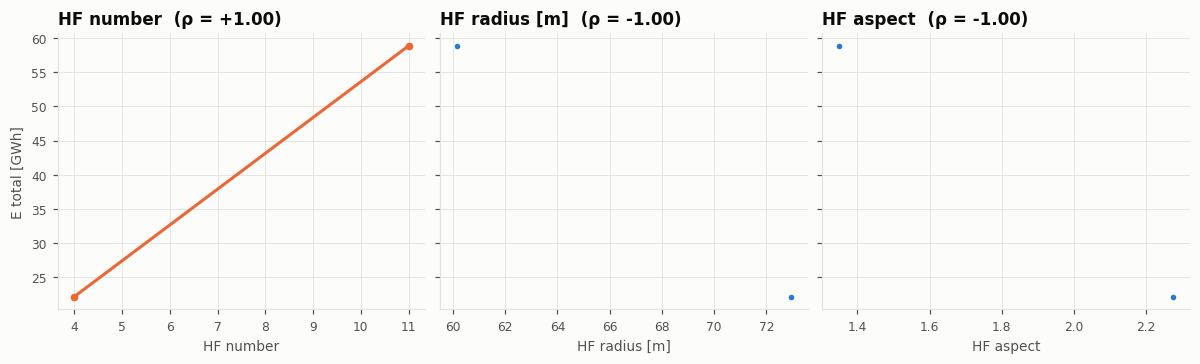

In [6]:
rows = []
for c in INPUTS:
    x = np.log10(df[c]) if c in LOG_INPUTS else df[c]
    pr = stats.pearsonr(x, y)
    sr = stats.spearmanr(df[c], df[RESPONSE])
    rows.append({"input": short(c), "Pearson r": pr.statistic, "p (Pearson)": pr.pvalue,
                 "Spearman ρ": sr.statistic, "p (Spearman)": sr.pvalue})
corr = pd.DataFrame(rows).set_index("input").sort_values("Spearman ρ", key=np.abs, ascending=False)
display(corr.round(4))

fig, axes = plt.subplots(1, len(INPUTS), figsize=(3.6 * len(INPUTS), 3.2), constrained_layout=True,
                         sharey=True, squeeze=False)
for ax, c in zip(axes[0], INPUTS):
    ax.scatter(df[c], df[RESPONSE], s=20, color=BLUE, edgecolor=SURFACE, linewidth=0.8, zorder=2)
    if c in INTEGER_INPUTS and df[c].nunique() <= 25:
        means = df.groupby(c)[RESPONSE].mean()
    else:
        q = pd.qcut(df[c], q=min(6, len(df) // 4), duplicates="drop")
        means = df.groupby(q, observed=True).agg(x=(c, "mean"), e=(RESPONSE, "mean")).set_index("x")["e"]
    ax.plot(means.index, means.values, color=ORANGE, linewidth=2, marker="o", markersize=4, zorder=3)
    if c in LOG_INPUTS:
        ax.set_xscale("log")
    if LOG_E:
        ax.set_yscale("log")
    ax.set_title(f"{short(c)}  (ρ = {corr.loc[short(c), 'Spearman ρ']:+.2f})")
    ax.set_xlabel(short(c))
axes[0][0].set_ylabel("E total [GWh]")
plt.show()

## 4. Multivariate regression

**Linear model**: $E$ on all swept inputs together. Because the sweep is a Latin hypercube
the inputs are nearly uncorrelated, so each coefficient is the effect of that input with
the others held fixed. Standardized coefficients (change in $E$ per one standard deviation
of the input) put the inputs on a common scale.

**With curvature and interactions**: adds squared terms and pairwise products, to test for
saturation (e.g. extra fractures adding less and less) and for one input changing another's
effect. Adjusted R² and cross-validated R² say whether the extra terms earn their place.

In [5]:
def ols(y, X):
    ''' Ordinary least squares with an intercept: coefficient table (coef, std err, t, p),
    R^2, adjusted R^2, fitted values and residuals (numpy/scipy only) '''
    A = np.column_stack([np.ones(len(y)), X.values])
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    resid = y - A @ coef
    n, k = A.shape
    dof = max(n - k, 1)
    s2 = resid @ resid / dof
    se = np.sqrt(np.diag(s2 * np.linalg.pinv(A.T @ A)))
    t = coef / se
    p = 2 * stats.t.sf(np.abs(t), dof)
    r2 = 1 - (resid @ resid) / np.sum((y - y.mean()) ** 2)
    table = pd.DataFrame({"coef": coef, "std err": se, "t": t, "p": p}, index=["intercept"] + list(X.columns))
    return table, r2, 1 - (1 - r2) * (n - 1) / dof, A @ coef, resid


table_lin, r2_lin, r2adj_lin, fit_lin, resid_lin = ols(y, X)
print(f"linear model for {y_name}: R^2 = {r2_lin:.3f}, adjusted {r2adj_lin:.3f}")
display(table_lin.round(4))

# curvature (squared terms; not for binary inputs) and pairwise interactions, on centred inputs
Xc = X - X.mean()
X_full = Xc.copy()
for col in Xc.columns:
    if Xc[col].nunique() > 2:
        X_full[f"{col}^2"] = Xc[col] ** 2
for a, b in itertools.combinations(Xc.columns, 2):
    X_full[f"{a} x {b}"] = Xc[a] * Xc[b]
n_terms = X_full.shape[1] + 1
if len(df) >= 2 * n_terms:
    table_full, r2_full, r2adj_full, fit_full, resid_full = ols(y, X_full)
    print(f"with curvature and interactions: R^2 = {r2_full:.3f}, adjusted {r2adj_full:.3f}")
    display(table_full.round(4))
else:
    table_full = None
    print(f"too few runs ({len(df)}) for {n_terms} terms with curvature and interactions "
          f"(need about {2 * n_terms}); skipped")

cv = KFold(n_splits=max(2, min(5, len(df) // 5)), shuffle=True, random_state=0)
cv_lin = cross_val_score(LinearRegression(), X, y, cv=cv, scoring="r2")
print(f"cross-validated R^2, linear: {cv_lin.mean():.3f} ± {cv_lin.std():.3f}")
if table_full is not None and len(df) >= 3 * n_terms:
    cv_full = cross_val_score(LinearRegression(), X_full, y, cv=cv, scoring="r2")
    print(f"cross-validated R^2, with curvature/interactions: {cv_full.mean():.3f} ± {cv_full.std():.3f}")

linear model for E [GWh]: R^2 = 0.989, adjusted 0.987


,coef,std err,t,p
intercept,20.6915,5.3083,3.8980,0.0007
HF number,4.9097,0.1144,42.9145,0.0000
HF radius [m],-0.0683,0.0541,-1.2616,0.2197
HF aspect,-5.2895,1.1470,-4.6115,0.0001


with curvature and interactions: R^2 = 0.994, adjusted 0.991


,coef,std err,t,p
intercept,59.7955,1.1634,51.3992,0.0000
HF number,4.9729,0.1024,48.5705,0.0000
HF radius [m],-0.0658,0.0505,-1.3020,0.2103
HF aspect,-4.9337,1.0532,-4.6844,0.0002
HF number^2,-0.0549,0.0238,-2.3052,0.0340
HF radius [m]^2,-0.0043,0.0053,-0.8195,0.4238
HF aspect^2,-0.0176,2.3667,-0.0074,0.9942
HF number x HF radius [m],-0.0122,0.0109,-1.1200,0.2783
HF number x HF aspect,-0.4919,0.2928,-1.6799,0.1113
HF radius [m] x HF aspect,0.0072,0.0848,0.0844,0.9337


cross-validated R^2, linear: 0.966 ± 0.034


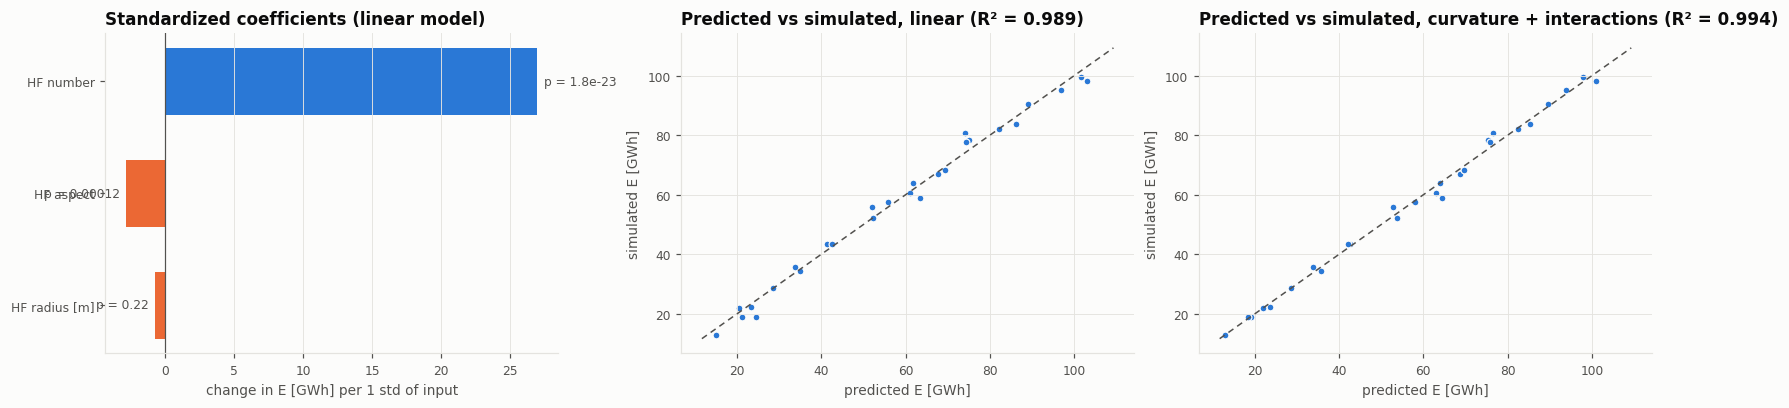

In [6]:
std_coef = table_lin["coef"].iloc[1:] * X.std().values
order = np.argsort(np.abs(std_coef.values))
pvals = table_lin["p"].iloc[1:].values[order]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), constrained_layout=True)
ax = axes[0]
ax.barh(np.arange(len(order)), std_coef.values[order],
        color=[BLUE if v > 0 else ORANGE for v in std_coef.values[order]], height=0.6)
for k, (v, p) in enumerate(zip(std_coef.values[order], pvals)):
    ax.annotate(f"p = {p:.2g}", (v, k), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", fontsize=8, color=TEXT_2)
ax.set_yticks(np.arange(len(order)), std_coef.index[order])
ax.axvline(0, color=TEXT_2, linewidth=0.8)
ax.set_xlabel(f"change in {y_name} per 1 std of input")
ax.set_title("Standardized coefficients (linear model)")
ax.grid(axis="y", visible=False)

back = (lambda v: 10 ** v) if LOG_E else (lambda v: v)
for ax, (name, fit, r2) in zip(axes[1:], (("linear", fit_lin, r2_lin),
                                           ("curvature + interactions", fit_full, r2_full) if table_full is not None
                                           else ("linear", fit_lin, r2_lin))):
    ax.scatter(back(fit), df[RESPONSE], s=20, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
    lim = [df[RESPONSE].min() * 0.9, df[RESPONSE].max() * 1.1]
    ax.plot(lim, lim, color=TEXT_2, linewidth=1, linestyle=(0, (4, 3)))
    if LOG_E:
        ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("predicted E [GWh]"); ax.set_ylabel("simulated E [GWh]")
    ax.set_title(f"Predicted vs simulated, {name} (R² = {r2:.3f})")
plt.show()

## 5. Random forest: importance and the shape of each effect

A random forest assumes no functional form. Permutation importance ranks the inputs by how
much shuffling each one degrades the forest's predictions; partial dependence shows the
predicted $E$ as one input varies with the others averaged over, which is the shape of that
input's effect (linear, saturating, or with an optimum).

cross-validated R^2, random forest: 0.881 ± 0.113  (linear: 0.966)


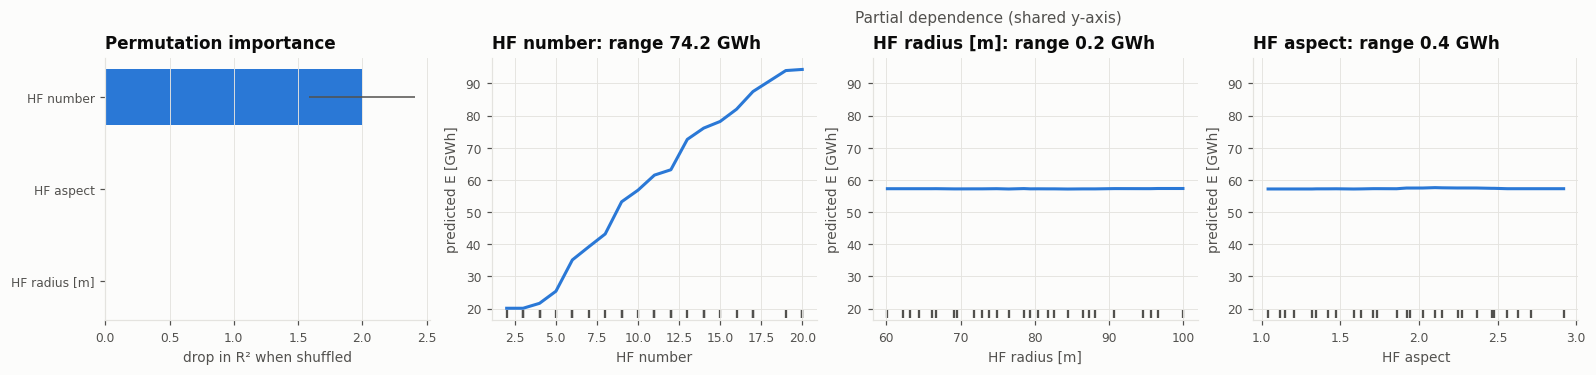

In [7]:
forest = RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=0)
cv_rf = cross_val_score(forest, X, y, cv=cv, scoring="r2")
print(f"cross-validated R^2, random forest: {cv_rf.mean():.3f} ± {cv_rf.std():.3f}  (linear: {cv_lin.mean():.3f})")
forest.fit(X, y)
imp = permutation_importance(forest, X, y, n_repeats=30, random_state=0)

fig, axes = plt.subplots(1, 1 + len(INPUTS), figsize=(3.6 * (1 + len(INPUTS)), 3.3), constrained_layout=True)
order = np.argsort(imp.importances_mean)
axes[0].barh(np.arange(len(order)), imp.importances_mean[order], xerr=imp.importances_std[order],
             color=BLUE, height=0.6, error_kw={"ecolor": TEXT_2, "lw": 1})
axes[0].set_yticks(np.arange(len(order)), X.columns[order])
axes[0].set_xlabel("drop in R² when shuffled")
axes[0].set_title("Permutation importance")
axes[0].grid(axis="y", visible=False)
curves = {}
for col in X.columns:
    pd_res = partial_dependence(forest, X, [col], grid_resolution=30)
    curves[col] = (pd_res["grid_values"][0], back(pd_res["average"][0]))
# one y-axis for all curves, so their heights compare directly
lo = min(v.min() for _, v in curves.values()); hi = max(v.max() for _, v in curves.values())
pad = 0.05 * (hi - lo)
for ax, col in zip(axes[1:], X.columns):
    grid, avg = curves[col]
    ax.plot(grid, avg, color=BLUE, linewidth=2)
    ax.scatter(X[col], np.full(len(X), lo - 0.5 * pad), marker="|", color=TEXT_2, s=30)   # where the runs are
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlabel(col); ax.set_ylabel("predicted E [GWh]")
    ax.set_title(f"{col}: range {avg.max() - avg.min():.1f} GWh")
fig.suptitle("Partial dependence (shared y-axis)", x=0.62, ha="center", fontsize=10, color=TEXT_2)
plt.show()

## 6. Best and worst designs

The five runs with the most and the least total production, with their swept inputs.

In [8]:
cols = ["jobname"] + INPUTS + [RESPONSE]
show = df[cols].rename(columns={c: short(c) for c in INPUTS} | {RESPONSE: "E total [GWh]"})
print("most heat:")
display(show.sort_values("E total [GWh]", ascending=False).head(5).round(3))
print("least heat:")
display(show.sort_values("E total [GWh]").head(5).round(3))

most heat:


,jobname,HF number,HF radius [m],HF aspect,E total [GWh]
7,lhs_hf_8,20,63.183,2.464,99.418
13,lhs_hf_15,20,74.870,2.024,98.072
8,lhs_hf_9,19,87.313,2.102,95.047
17,lhs_hf_19,17,71.800,1.946,90.361
4,lhs_hf_5,17,79.407,2.366,83.893


least heat:


,jobname,HF number,HF radius [m],HF aspect,E total [GWh]
21,lhs_hf_25,2,84.450,1.858,12.951
12,lhs_hf_14,3,95.643,1.475,18.870
2,lhs_hf_3,3,69.572,1.147,18.906
11,lhs_hf_13,4,99.995,2.478,22.036
1,lhs_hf_2,4,72.933,2.275,22.199


## Notes

- Weak effects (small standardized coefficients, p near 0.05, flat partial dependence)
  should be checked with more runs; section 1 warns when there are few runs per input.
- Settings not swept (listed in section 1) are held fixed and cannot show up here.
- To add runs: raise `N_samples` (or change `SWEEP`) in `make_yaml_file.py`, regenerate,
  and rerun `bash runs/<sweep>/run_all.sh`; finished runs are skipped and every new run
  adds its row to the master CSV.